In [1]:
# %load_ext autoreload
# %autoreload 2
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.parent.parent.parent.parent.parent
sys.path.insert(0, str(PROJECT_ROOT))
print(PROJECT_ROOT)

from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson
import scanpy as sc
import anndata
import pandas as pd
from matplotlib.pyplot import rc_context
import anndata
import seaborn as sns
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
import scipy.sparse as sp
print("CUDA Available: ", torch.cuda.is_available())
print("Number of GPUs: ", torch.cuda.device_count())
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import ndtest
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import DistanceMetric
import numpy as np
import os
from matplotlib import font_manager
import matplotlib.patches as mpatches
from scipy.ndimage import gaussian_filter
from matplotlib.legend_handler import HandlerTuple
font_manager.fontManager.addfont("../../../.././arial.ttf")
import numpy as np
import matplotlib.pyplot as plt
from brokenaxes import brokenaxes

plt.rcParams["font.family"] = "Arial"
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 17,
    "pdf.fonttype": 42,
})
plt.rcParams["hatch.linewidth"] = 1


/lustre/work/yaolab/mzhou10/squidiff_practice/Squidiff/project_v3
CUDA Available:  True
Number of GPUs:  1


In [2]:
arr = [0.0778,0.0390,0.0325,0.0435, 0.0627,0.0841,0.0426,0.3959,  0.1216,0.5250,0.1006,0.6389,
       0.0311,0.7343,0.1889,0.8552, 0.0578,0.8807,0.1580,0.8983,  0.1724,0.9007,0.0610,0.9119]

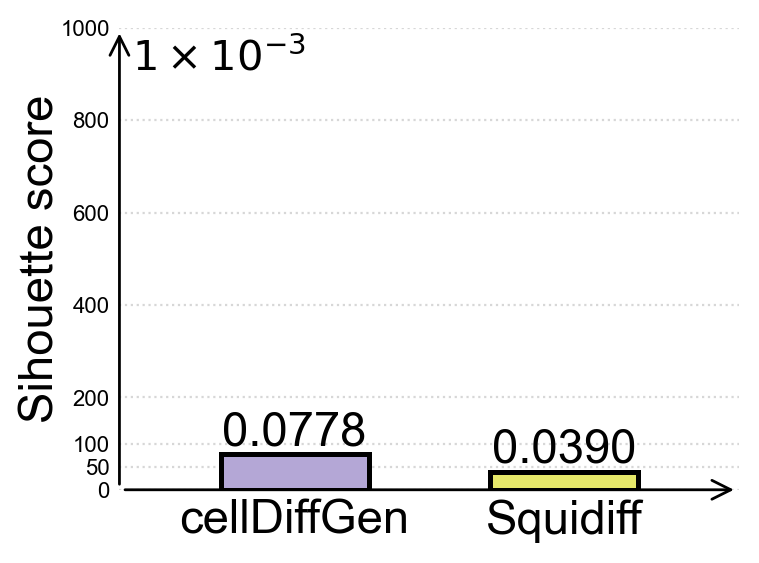

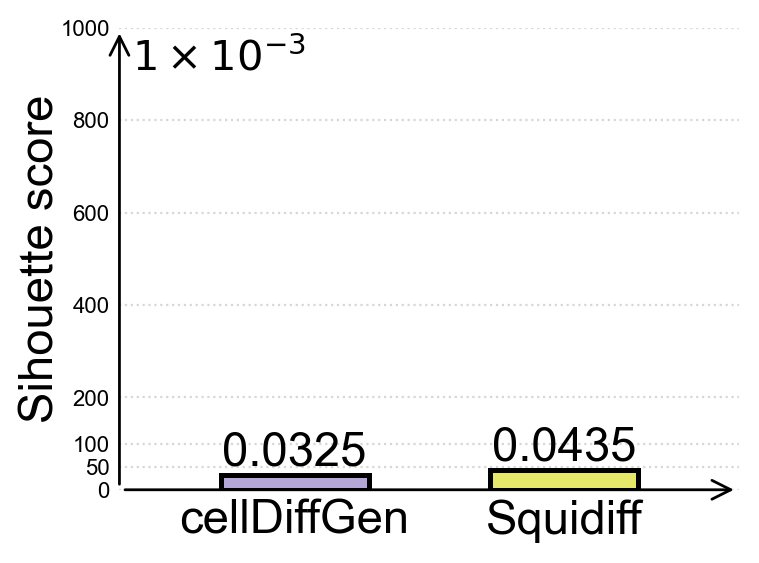

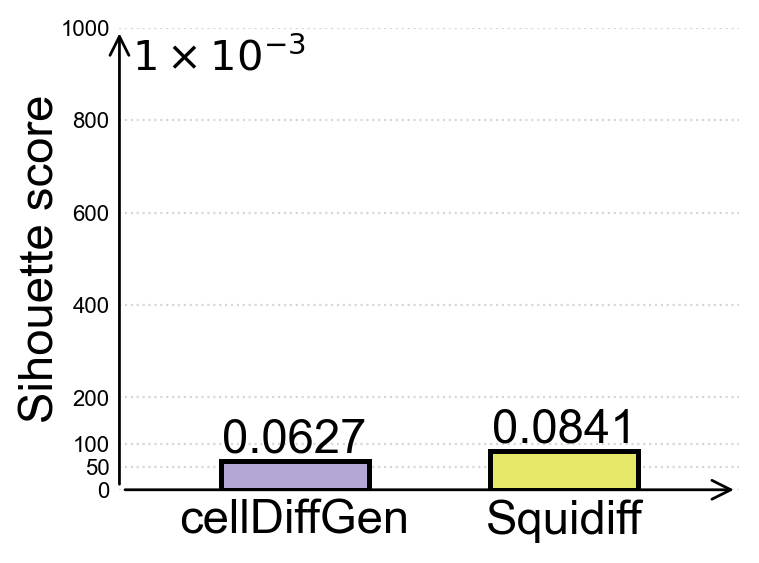

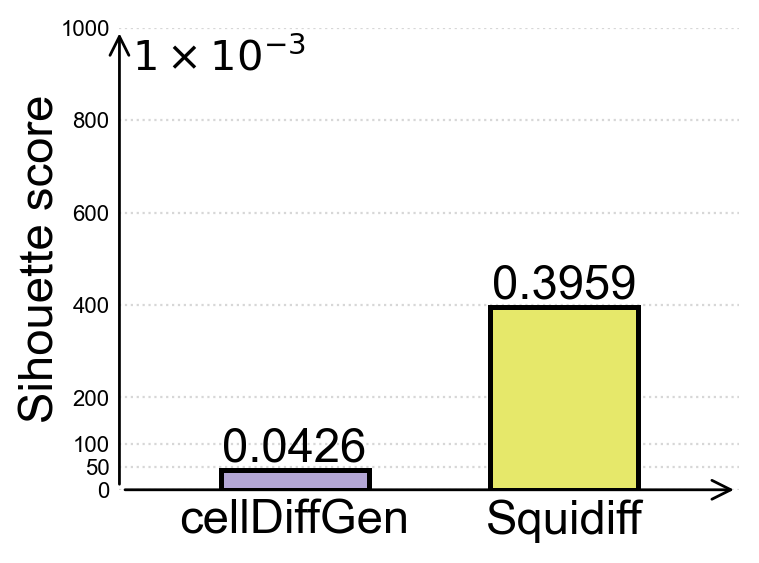

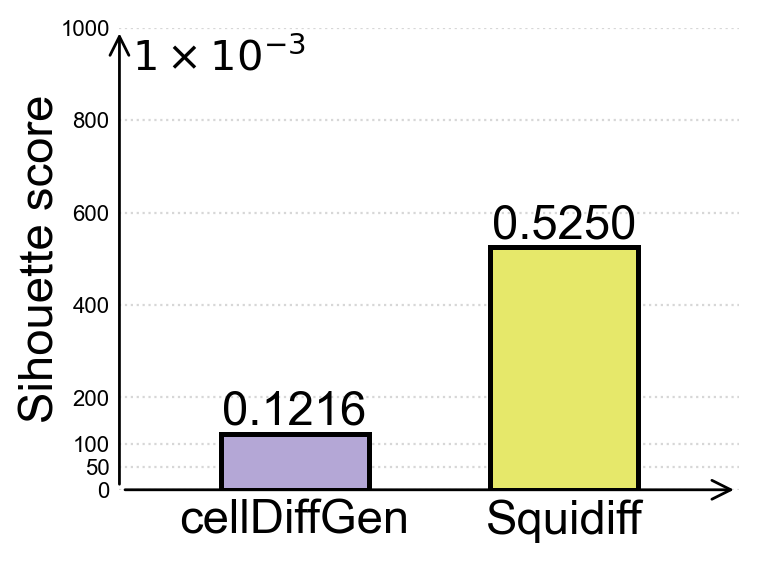

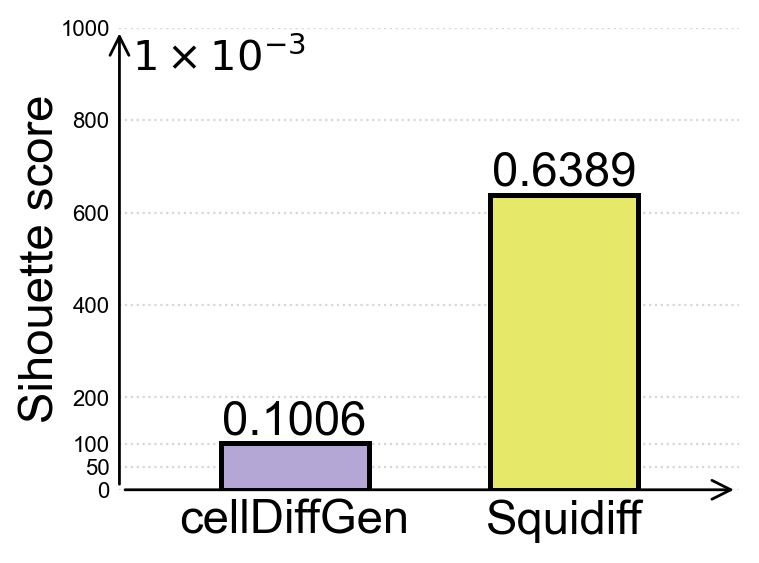

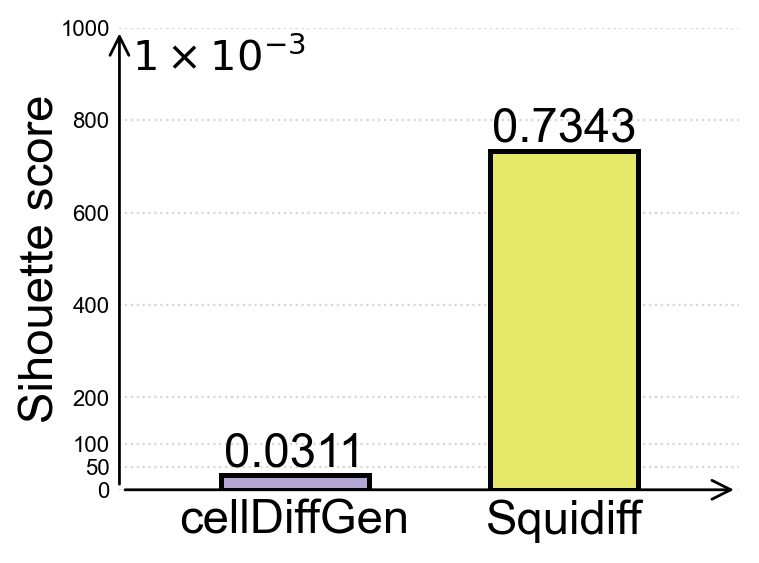

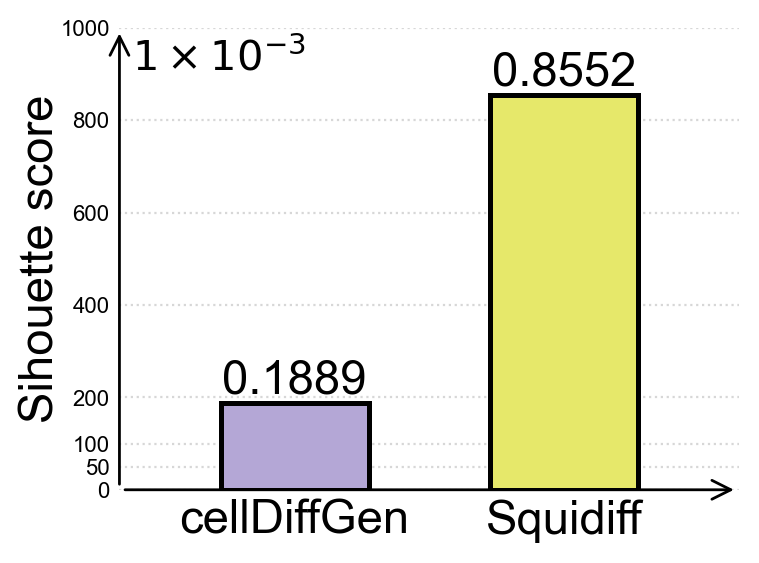

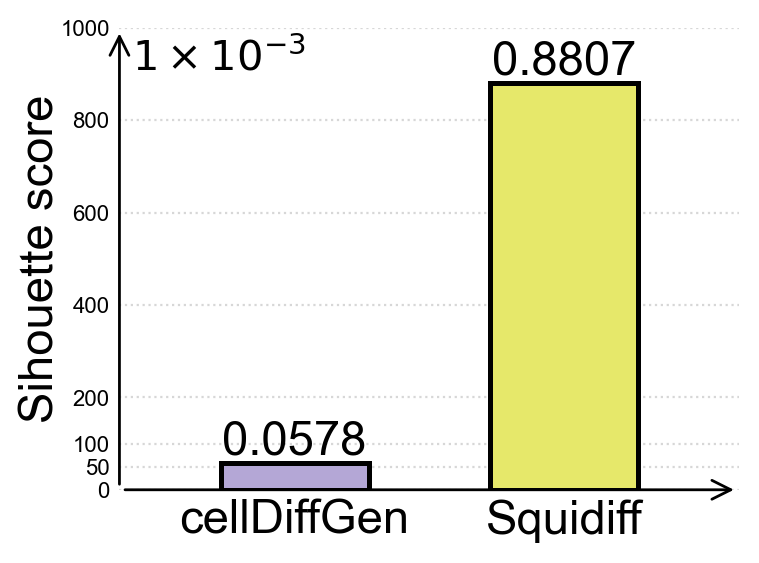

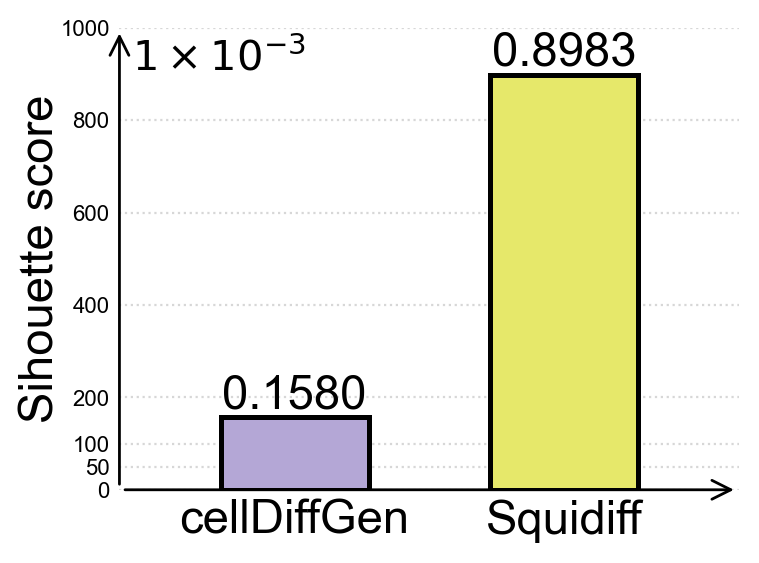

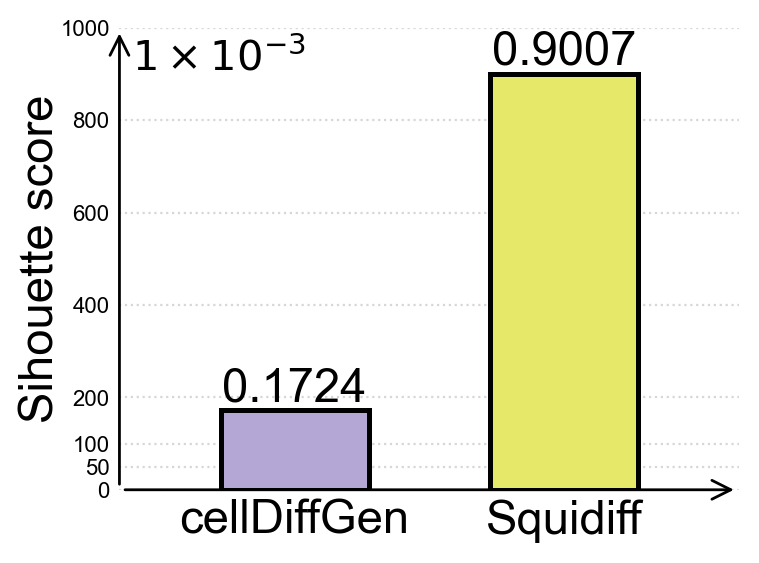

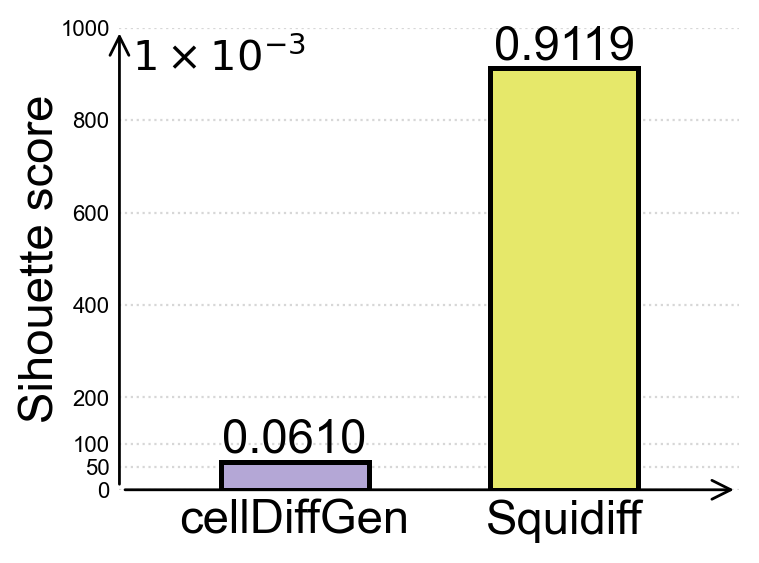

In [3]:
import numpy as np
import matplotlib.pyplot as plt
for index, i in enumerate([100, 200, 203, 250, 300, 400, 500,1000,2000,5000,10000,11231]):
    values = np.array(arr[2*index:2*index+2]) * 1000

    fig, ax = plt.subplots(figsize=(4, 3), dpi=200)

    bars = ax.bar(
        [0, 1], values,
        width=0.55,
        color=["#B4A7D6", "#E6E86A"],
        edgecolor="black",
        linewidth=1.8
    )

    ax.bar_label(
    bars,
    labels=[f"{v / 1000:.4f}" for v in values],
    padding=0
    )
    ax.margins(y=0.35)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["cellDiffGen", "Squidiff"])
    ax.set_xlim(-0.65, 1.65)
    # ax.set_ylim(0, 120)
    # plt.rcParams["mathtext.rm"] = "Arial"
    ax.text(
    0.02, 0.98, r"$1 \times 10^{-3}$",
    transform=ax.transAxes, fontfamily="Arial",
    ha="left", va="top", fontsize=15
    )
    ax.set_ylabel("Sihouette score", labelpad=-1, fontname="Arial")
    ax.tick_params(length=0)
    ax.set_ylim(0, 1000)
    ax.set_yticks([0, 50,100,200,400,600,800,1000])
    ax.tick_params(axis="y", labelsize=8)
    ax.yaxis.grid(True, linestyle=":", linewidth=0.8, alpha=0.5)
    ax.set_axisbelow(True)
    # # Hide borders and add arrow axes
    for spine in ax.spines.values():
        spine.set_visible(False)
    # ax.spines["top"].set_visible(False)
    # ax.spines["right"].set_visible(False)
    for end in [(1.0, 0), (0, 1.0)]:
        ax.annotate(
            "", xy=end, xytext=(0, 0),
            xycoords="axes fraction",
            arrowprops=dict(arrowstyle="->", lw=1),
            annotation_clip=False
        )

    fig.savefig(f"bar_plot_gene_{i}.pdf", bbox_inches="tight")
    plt.show()